In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [5]:
#Load Amazon Data
df =pd.read_csv("/Users/arjolaarapi-gjini/Desktop/amz_uk_price_prediction_dataset.csv")

In [7]:
# Check first 5 obs of the data
df.head(5)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB


In [14]:
# Crosstabs

crosstab = pd.crosstab(df['category'], df['isBestSeller'])
print(crosstab)


isBestSeller                    False  True 
category                                    
3D Printers                       247      1
3D Printing & Scanning           4065      2
Abrasive & Finishing Products     245      5
Action Cameras                   1696      1
Adapters                          251      3
...                               ...    ...
Wind Instruments                  243      7
Window Treatments                 234      5
Women                           17559    213
Women's Sports & Outdoor Shoes   1939     20
eBook Readers & Accessories       246      0

[296 rows x 2 columns]


In [11]:
# Calculate proportion of Best Seller Products
best_seller_prop = crosstab.div(crosstab.sum(axis=1), axis=0)[True]

best_seller_prop_sorted = best_seller_prop.sort_values(ascending=False)

best_seller_prop_sorted.head(10)

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Mirrors                           0.028000
Wind Instruments                  0.028000
Name: True, dtype: float64

In [ ]:
# We see that Groceries have the highest proportion of Best Selling products

In [22]:
# Chi-square test statistic
# Get unique values
categories = df['category'].unique()
best_seller_status = df['isBestSeller'].unique()
print(best_seller_status)
# Build contingency table manually
contingency = np.zeros((len(categories), len(best_seller_status)))

for i, cat in enumerate(categories):
    for j, status in enumerate(best_seller_status):
        contingency[i, j] = ((df['category']==cat) & (df['isBestSeller']==status)).sum()

contingency

[False  True]


array([[8.73300e+03, 1.20000e+01],
       [8.79800e+03, 0.00000e+00],
       [8.87600e+03, 3.00000e+01],
       [9.16900e+03, 1.40000e+01],
       [2.52000e+02, 2.00000e+00],
       [4.44600e+03, 2.30000e+01],
       [5.10000e+02, 4.00000e+00],
       [4.27000e+02, 1.00000e+00],
       [5.30000e+01, 1.00000e+00],
       [4.75000e+02, 9.00000e+00],
       [4.36000e+02, 3.00000e+00],
       [5.25600e+03, 2.00000e+00],
       [2.48000e+02, 2.00000e+00],
       [1.07000e+02, 0.00000e+00],
       [1.73870e+04, 4.80000e+01],
       [8.42400e+03, 1.46000e+02],
       [8.63900e+03, 2.40000e+01],
       [9.34800e+03, 1.60000e+01],
       [8.73600e+03, 6.00000e+00],
       [3.49000e+02, 0.00000e+00],
       [2.43000e+02, 0.00000e+00],
       [9.29600e+03, 8.70000e+01],
       [1.17020e+04, 8.70000e+01],
       [8.35935e+05, 3.30000e+02],
       [9.38800e+03, 7.00000e+00],
       [2.45000e+02, 5.00000e+00],
       [2.48100e+03, 2.00000e+00],
       [2.87000e+02, 3.00000e+00],
       [2.59000e+02,

In [15]:
# Expected frequencies
n = contingency.sum()
row_sums = contingency.sum(axis=1, keepdims=True)
col_sums = contingency.sum(axis=0, keepdims=True)
expected = row_sums @ col_sums / n

# Chi-square statistic
chi2 = ((contingency - expected)**2 / expected).sum()

# Degrees of freedom
dof = (len(categories)-1) * (len(best_seller_status)-1)

# p-value approximation using NumPy: you need scipy.stats.chi2.sf for exact p
# But we can just report chi2 and dof if we avoid scipy
chi2, dof

(np.float64(36540.20270061387), 295)

In [ ]:
# Best seller status not indipendent of product category

In [17]:
# Cramer's V (Strength of Association)
n = crosstab.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(crosstab.shape)-1)))

print("Cramer's V:", cramers_v)
# Cramer's V shows weak association betweem categories and best seller products status - other factors might be more important

Cramer's V: 0.1222829439760564


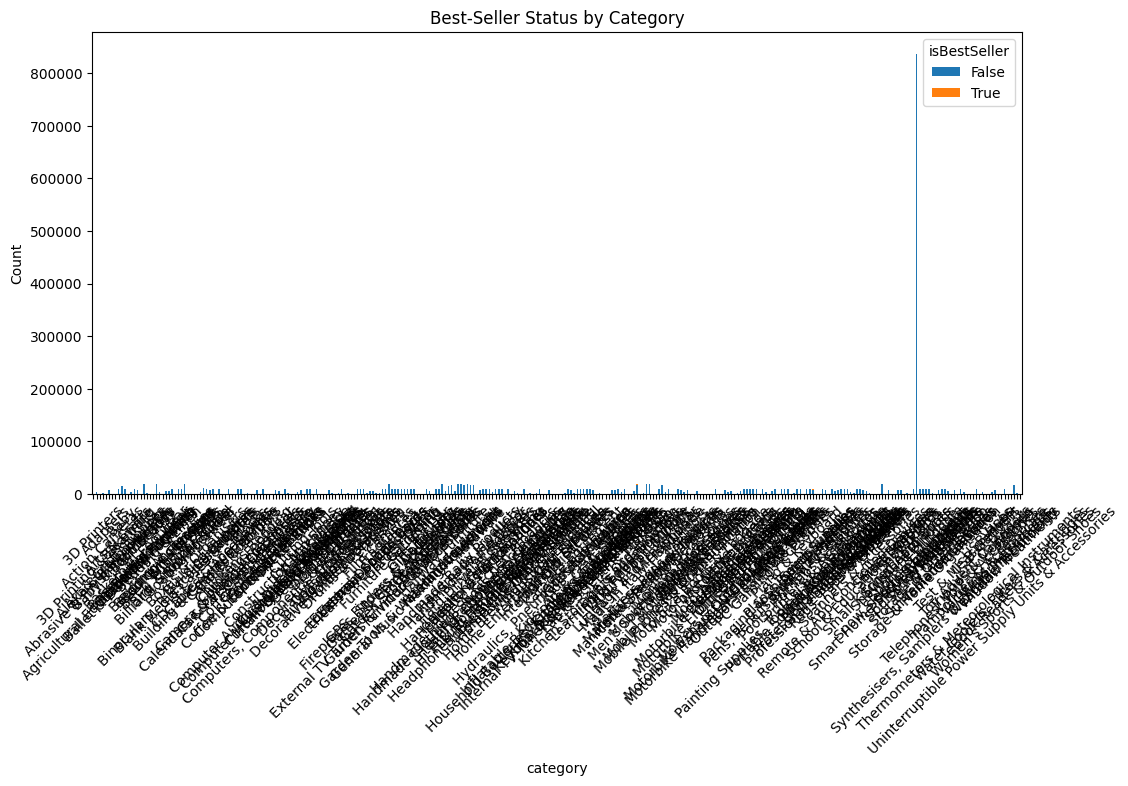

In [19]:
ct.plot(kind='bar', stacked=True, figsize=(12,6))
plt.title("Best-Seller Status by Category")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

In [21]:
#Create a new dataframe without outliers
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_no_outliers = df[(df['price'] >=lower) & (df['price'] <= upper)]
df_no_outliers = df[(df['price'] >= lower) & (df['price'] <= upper)]

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts', 'Handmade Home Décor',
       'Luggage and travel gear', 'Women', 'Fragrances',
       'Handmade Kitchen & Dining', 'Handmade Artwork',
       'Handmade Home & Kitchen Products', 'Handmade Jewellery', 'Men',
       'Baby'],
      dtype='str', name='category')


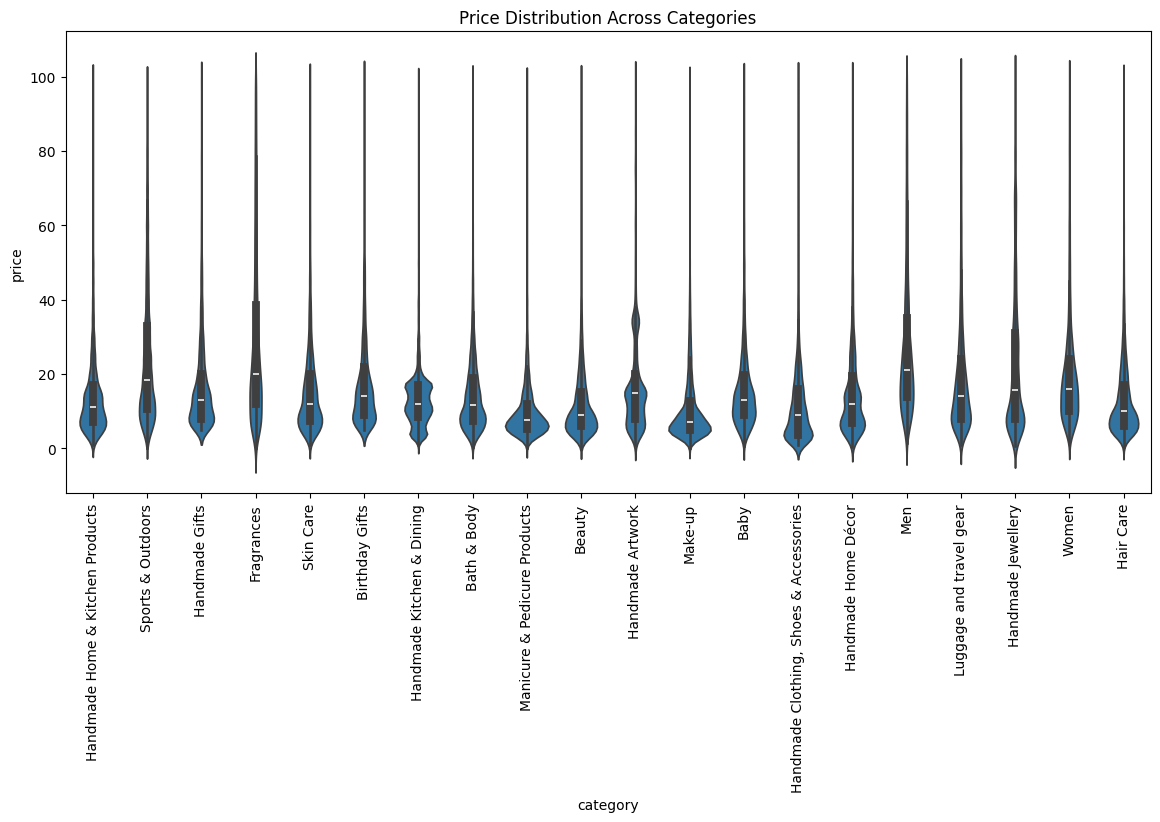

In [23]:
# Distribution of Prices Accross Different Categories
top20 = df_no_outliers['category'].value_counts().head(20).index
print(top20)

plt.figure(figsize=(14,6))
sns.violinplot(data=df_no_outliers[df_no_outliers['category'].isin(top20)],
               x='category', y='price')

plt.xticks(rotation=90)
plt.title("Price Distribution Across Categories")
plt.show()


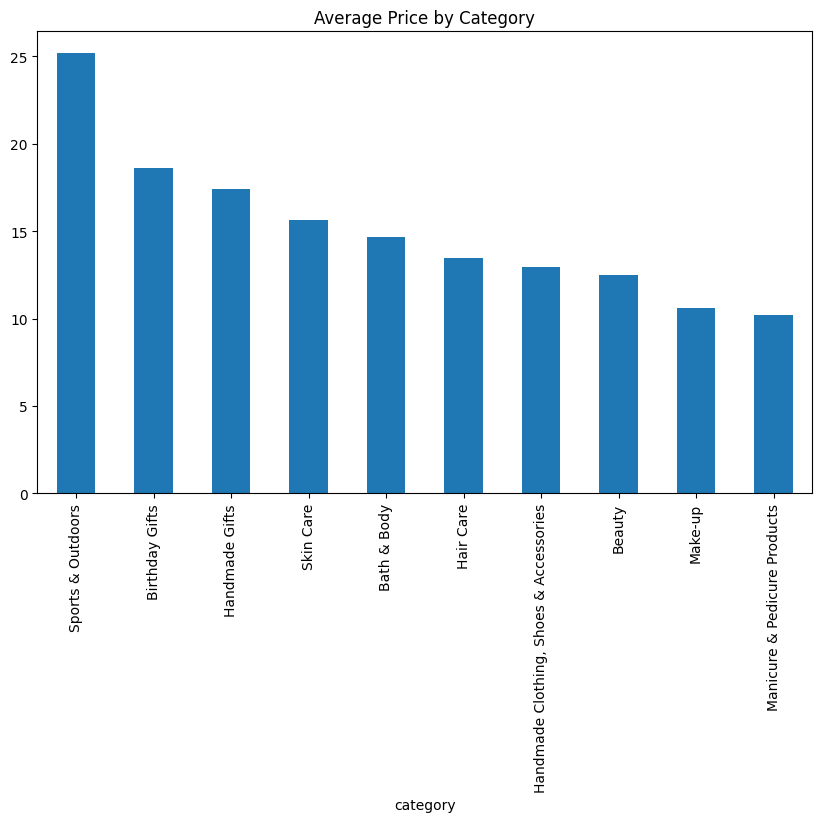

In [29]:
# Boxplot
top10 = df_no_outliers['category'].value_counts().head(10).index

avg_price = df_no_outliers[df_no_outliers['category'].isin(top10)] \
            .groupby('category')['price'].mean() \
            .sort_values(ascending=False)

avg_price.plot(kind='bar', figsize=(10,6))
plt.title("Average Price by Category")
plt.xticks(rotation=90)
plt.show()

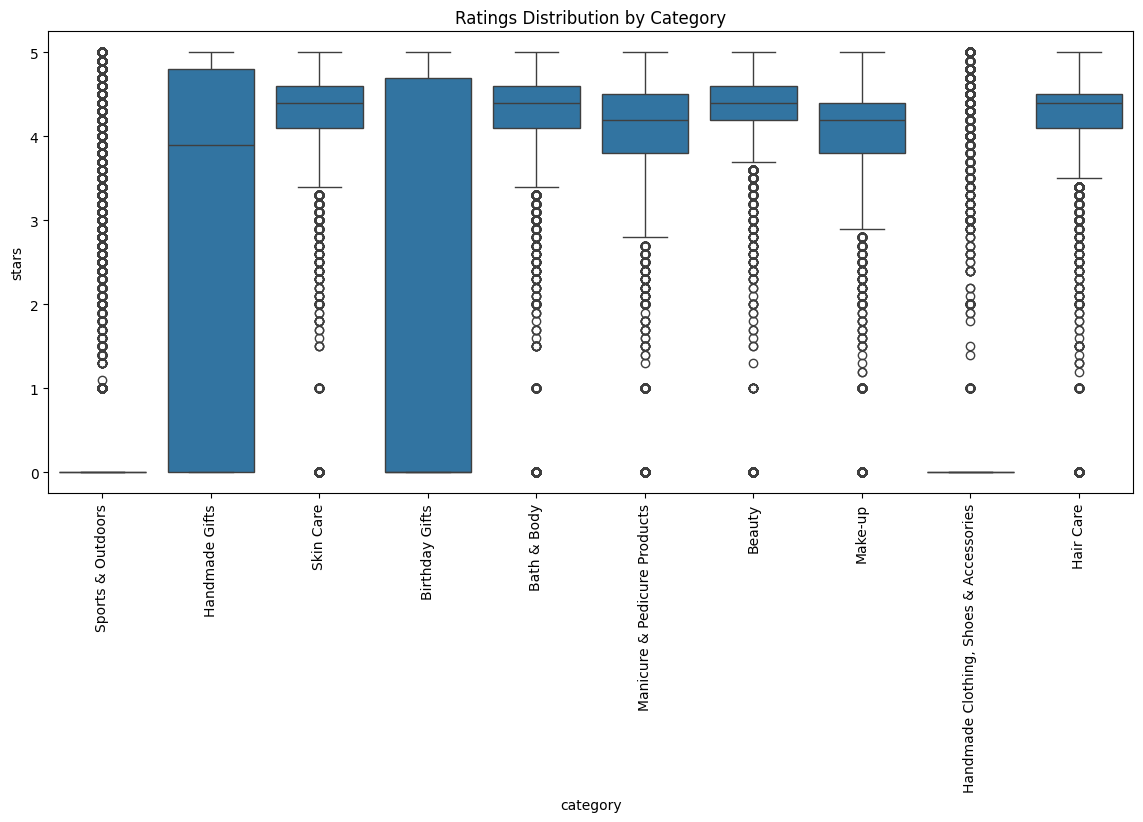

In [30]:
top10 = df_no_outliers['category'].value_counts().head(10).index

plt.figure(figsize=(14,6))
sns.boxplot(data=df_no_outliers[df_no_outliers['category'].isin(top10)],
            x='category', y='stars')

plt.xticks(rotation=90)
plt.title("Ratings Distribution by Category")
plt.show()

In [31]:
df_no_outliers.groupby('category')['stars'].median().sort_values(ascending=False).head()
#The median is the best measure of centrality to report because it is unaffected by outliers.
# Many product categories have many outliers, and for these products reporting average customer ratings wuld not make sense 

category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Name: stars, dtype: float64

In [ ]:
correlation = df_no_outliers['price'].corr(df_no_outliers['stars'])
print("Correlation:", correlation)

In [32]:
correlation = df_no_outliers['price'].corr(df_no_outliers['stars'])
print("Correlation:", correlation)
# Weak Correlation between prices and customer evalutions

Correlation: -0.07767299878181352


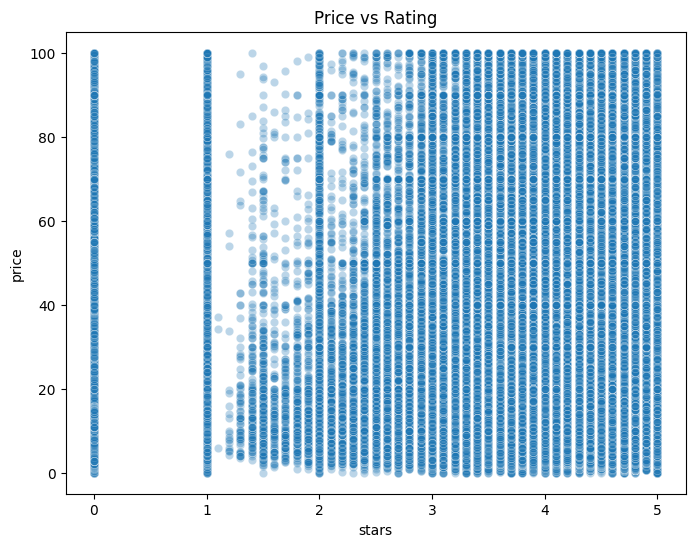

In [33]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df_no_outliers, x='stars', y='price', alpha=0.3)
plt.title("Price vs Rating")
plt.show()
# Scatterplot reveals no correlation

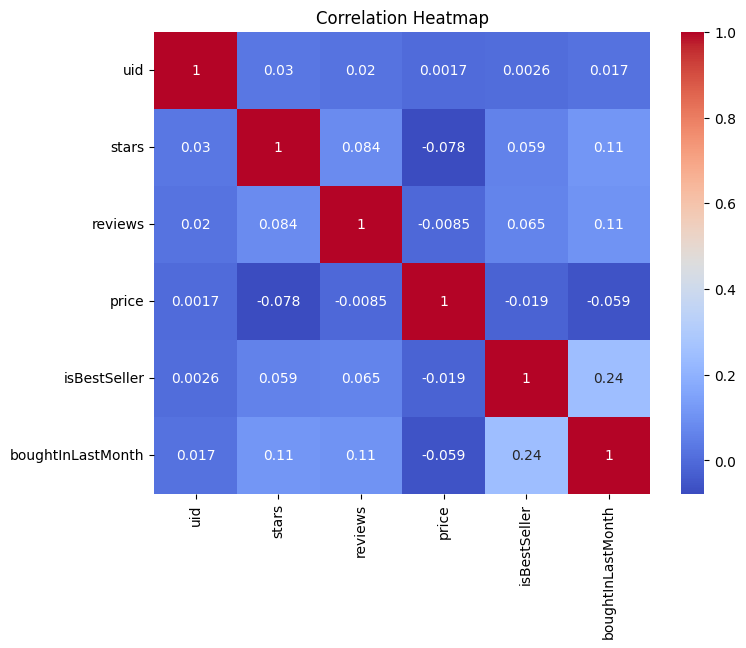

In [34]:
plt.figure(figsize=(8,6))
sns.heatmap(df_no_outliers.corr(numeric_only=True),
            annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()
# Correlation HeatMap Reveals Weak relationships betweem the various variables in the dataset. The correlation between price and ratings is weak, suggesting that higher prices do not necessarily translate into better customer evaluations. 